Week 1 Notebook for Milestone 1

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor
from patsy import dmatrix
from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

In [3]:
cols = ['MENTHLTH','PHYSHLTH','INCOME3','EMPLOY1','_HLTHPL2','MEDCOST1','GENHLTH','_AGE_G','_BMI5']
brfss = pd.read_sas('LLCP2024.XPT ', format='xport')[cols]

for c in ['MENTHLTH', 'PHYSHLTH']:
    brfss[c] = brfss[c].replace({88: 0, 77: np.nan, 99: np.nan})
brfss['INCOME3'] = brfss['INCOME3'].where(brfss['INCOME3'].between(1, 11))
brfss['GENHLTH'] = brfss['GENHLTH'].where(brfss['GENHLTH'].between(1, 5))

brfss['NO_INSURANCE'] = brfss['_HLTHPL2'].map({1: 0, 2: 1})
brfss['COST_BARRIER'] = brfss['MEDCOST1'].map({1: 1, 2: 0})

brfss['EMPLOY'] = brfss['EMPLOY1'].map({1: 'Employed', 2: 'SelfEmployed', 3: 'OutOfWork1yr+',
                                       4: 'OutOfWork<1yr', 5: 'Homemaker', 6: 'Student',
                                       7: 'Retired', 8: 'UnableToWork'})
brfss['BMI'] = brfss['_BMI5'] / 100
brfss = brfss.rename(columns={'_AGE_G': 'AGE_G'})

brfss = (brfss[['MENTHLTH','PHYSHLTH','INCOME3','GENHLTH','AGE_G','BMI',
                'NO_INSURANCE','COST_BARRIER','EMPLOY']]
         .dropna().sample(50_000, random_state=42).reset_index(drop=True))
print(brfss.shape); brfss.describe().round(2)

(50000, 9)


,MENTHLTH,PHYSHLTH,INCOME3,GENHLTH,AGE_G,BMI,NO_INSURANCE,COST_BARRIER
count,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00,50000.00
mean,4.52,4.59,7.08,2.62,4.39,28.81,0.05,0.09
std,8.39,8.87,2.43,1.04,1.59,6.64,0.22,0.29
min,0.00,0.00,1.00,1.00,1.00,12.05,0.00,0.00
25%,0.00,0.00,6.00,2.00,3.00,24.37,0.00,0.00
50%,0.00,0.00,7.00,3.00,5.00,27.60,0.00,0.00
75%,5.00,4.00,9.00,3.00,6.00,32.01,0.00,0.00
max,30.00,30.00,11.00,5.00,6.00,98.44,1.00,1.00


50,000-respondent BRFSS 2024 sample. Target: poor mental health days (0–30). Physical health days and BMI are continuous; income, general health and age are ordinal codes treated as numeric; insurance and cost barrier are binary; employment is one-hot encoded.

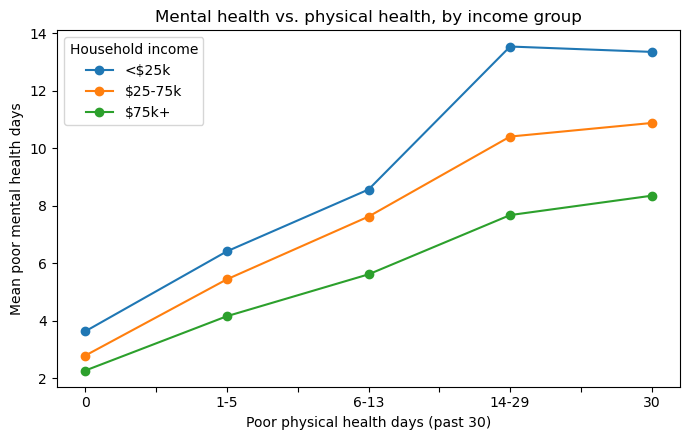

In [4]:
plot_df = brfss.assign(
    PHYS_BIN=pd.cut(brfss['PHYSHLTH'], [-1, 0, 5, 13, 29, 30], labels=['0','1-5','6-13','14-29','30']),
    INC_GROUP=pd.cut(brfss['INCOME3'], [0, 4, 7, 11], labels=['<$25k','$25-75k','$75k+']))

(plot_df.groupby(['PHYS_BIN','INC_GROUP'], observed=True)['MENTHLTH'].mean()
        .unstack().plot(marker='o', figsize=(7, 4.5)))
plt.xlabel('Poor physical health days (past 30)'); plt.ylabel('Mean poor mental health days')
plt.title('Mental health vs. physical health, by income group')
plt.legend(title='Household income'); plt.tight_layout(); plt.show()

Mental health days rise with physical health days in every income group, most steeply for low-income respondents. This motivates testing interaction terms.

In [5]:
train, test = train_test_split(brfss, test_size=0.2, random_state=42)

m1 = 'MENTHLTH ~ PHYSHLTH + INCOME3 + GENHLTH + AGE_G + BMI + NO_INSURANCE + COST_BARRIER + C(EMPLOY)'
m2 = m1 + ' + I(PHYSHLTH**2) + I(BMI**2) + I(AGE_G**2)'
m3 = m2 + ' + PHYSHLTH:INCOME3 + PHYSHLTH:COST_BARRIER + PHYSHLTH:AGE_G + INCOME3:NO_INSURANCE'
formulas = {'M1 main effects': m1, 'M2 + polynomial': m2, 'M3 + interactions': m3}

fits, rows = {}, []
for name, f in formulas.items():
    fit = smf.ols(f, data=train).fit()
    pred = fit.predict(test)
    fits[name] = fit
    rows.append({'model': name, 'n_params': len(fit.params),
                 'train_R2': fit.rsquared, 'adj_R2': fit.rsquared_adj,
                 'test_R2': r2_score(test['MENTHLTH'], pred),
                 'test_RMSE': np.sqrt(mean_squared_error(test['MENTHLTH'], pred)),
                 'AIC': fit.aic})
results = pd.DataFrame(rows).round(4); results

,model,n_params,train_R2,adj_R2,test_R2,test_RMSE,AIC
0,M1 main effects,15,0.2074,0.2072,0.2011,7.5695,274203.3210
1,M2 + polynomial,18,0.2122,0.2118,0.2049,7.5517,273968.7996
2,M3 + interactions,22,0.2201,0.2197,0.2054,7.5495,273574.7282


Adding polynomial and interaction terms lowered AIC and raised test R² from 0.201 to 0.205. That’s a real but small gain: most of the explainable variance is already captured by the main effects. Train and test R² stay close, so there’s no meaningful overfitting.

In [6]:
coefs = fits['M3 + interactions'].summary2().tables[1]
coefs[coefs.index.str.contains(r':|\*\*')].round(4)

,Coef.,Std.Err.,t,P>|t|,[0.025,0.975]
I(PHYSHLTH ** 2),-0.0082,0.0006,-13.5791,0.0000,-0.0094,-0.0070
I(BMI ** 2),0.0019,0.0004,5.3072,0.0000,0.0012,0.0026
I(AGE_G ** 2),-0.0232,0.0200,-1.1572,0.2472,-0.0624,0.0161
PHYSHLTH:INCOME3,-0.0157,0.0017,-8.9881,0.0000,-0.0192,-0.0123
PHYSHLTH:COST_BARRIER,0.0198,0.0126,1.5716,0.1161,-0.0049,0.0445
PHYSHLTH:AGE_G,-0.0499,0.0031,-15.9106,0.0000,-0.0561,-0.0438
INCOME3:NO_INSURANCE,0.4622,0.0737,6.2744,0.0000,0.3178,0.6065


Physical health hurts mental health more for lower-income and younger respondents (both interactions p < .001). The age interaction is the strongest. The negative PHYSHLTH² term means the effect flattens at high day counts. The age² and cost-barrier interaction terms are not significant.

In [7]:
def vif_table(formula, data):
    X = dmatrix(formula.split('~')[1], data, return_type='dataframe')
    return pd.Series([variance_inflation_factor(X.values, i) for i in range(1, X.shape[1])],
                     index=X.columns[1:])

cont = ['PHYSHLTH', 'INCOME3', 'AGE_G', 'BMI']
train_c = train.copy()
train_c[cont] = train_c[cont] - train[cont].mean()

vif = pd.DataFrame({'M1 raw': vif_table(m1, train),
                    'M3 raw': vif_table(m3, train),
                    'M3 centered': vif_table(m3, train_c)}).round(2)
print(vif)

print('R2 raw:', round(smf.ols(m3, train).fit().rsquared, 5),
      '| R2 centered:', round(smf.ols(m3, train_c).fit().rsquared, 5))

                            M1 raw  M3 raw  M3 centered
AGE_G                         1.94   42.95         3.30
BMI                           1.07   19.99         1.53
C(EMPLOY)[T.Homemaker]        1.06    1.06         1.06
C(EMPLOY)[T.OutOfWork1yr+]    1.07    1.07         1.07
C(EMPLOY)[T.OutOfWork<1yr]    1.06    1.07         1.07
C(EMPLOY)[T.Retired]          2.15    2.59         2.59
C(EMPLOY)[T.SelfEmployed]     1.14    1.14         1.14
C(EMPLOY)[T.Student]          1.10    1.16         1.16
C(EMPLOY)[T.UnableToWork]     1.42    1.46         1.46
COST_BARRIER                  1.18    1.75         1.28
GENHLTH                       1.54    1.57         1.57
I(AGE_G ** 2)                  NaN   47.42         2.06
I(BMI ** 2)                    NaN   19.85         1.44
I(PHYSHLTH ** 2)               NaN   17.06         8.25
INCOME3                       1.37    1.77         1.45
INCOME3:NO_INSURANCE           NaN    7.13         1.52
NO_INSURANCE                  1.16    7.46      

Main-effects VIFs are all below 2.2. Squared and interaction terms push VIFs up to around 47, which is structural multicollinearity. Centering brings most back under 3.3 with identical R². PHYSHLTH stays near 9 because it is heavily skewed.

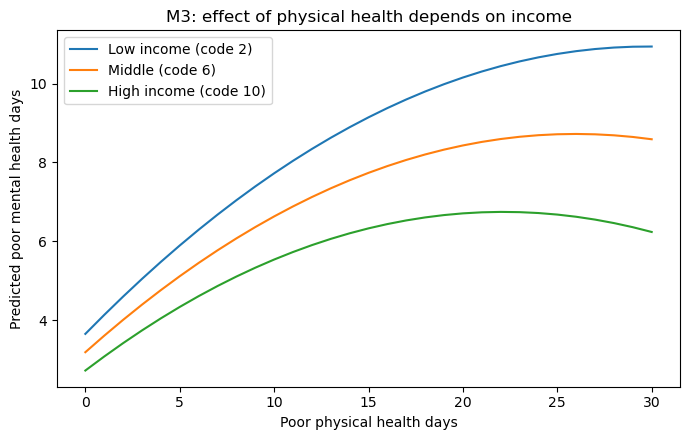

In [8]:
grid = pd.DataFrame({'PHYSHLTH': np.arange(0, 31)})
base = {'GENHLTH': train['GENHLTH'].median(), 'AGE_G': train['AGE_G'].median(),
        'BMI': train['BMI'].median(), 'NO_INSURANCE': 0, 'COST_BARRIER': 0,
        'EMPLOY': train['EMPLOY'].mode()[0]}

plt.figure(figsize=(7, 4.5))
for inc, label in [(2, 'Low income (code 2)'), (6, 'Middle (code 6)'), (10, 'High income (code 10)')]:
    g = grid.assign(INCOME3=inc, **base)
    plt.plot(g['PHYSHLTH'], fits['M3 + interactions'].predict(g), label=label)
plt.xlabel('Poor physical health days'); plt.ylabel('Predicted poor mental health days')
plt.title('M3: effect of physical health depends on income'); plt.legend()
plt.tight_layout(); plt.show()

Predicted mental health days climb faster for low-income respondents as physical health worsens.

   degree  n_features  train_RMSE  cv_RMSE
0       1           7      7.4795   7.4814
1       2          35      7.3779   7.3878
2       3         119      7.3544   7.3948
3       4         329      7.3112   7.4597
4       5         791      7.2456   8.7552


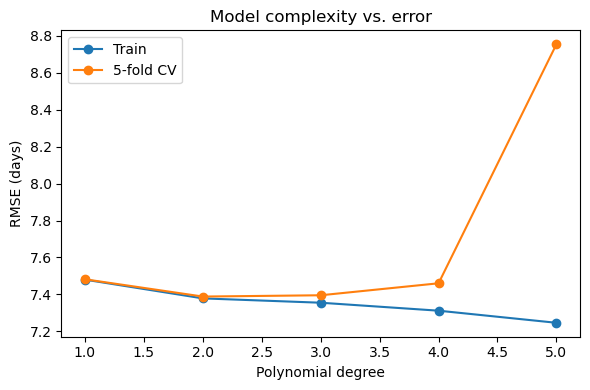

In [9]:
num = ['PHYSHLTH','INCOME3','GENHLTH','AGE_G','BMI','NO_INSURANCE','COST_BARRIER']
X, y = train[num], train['MENTHLTH']
cv = KFold(5, shuffle=True, random_state=42)

sweep = []
for d in range(1, 6):
    pipe = make_pipeline(PolynomialFeatures(d, include_bias=False), StandardScaler(), LinearRegression())
    s = cross_validate(pipe, X, y, cv=cv, scoring='neg_root_mean_squared_error', return_train_score=True)
    sweep.append({'degree': d, 'n_features': PolynomialFeatures(d).fit(X).n_output_features_ - 1,
                  'train_RMSE': -s['train_score'].mean(), 'cv_RMSE': -s['test_score'].mean()})
sweep = pd.DataFrame(sweep).round(4); print(sweep)

plt.figure(figsize=(6, 4))
plt.plot(sweep['degree'], sweep['train_RMSE'], 'o-', label='Train')
plt.plot(sweep['degree'], sweep['cv_RMSE'], 'o-', label='5-fold CV')
plt.xlabel('Polynomial degree'); plt.ylabel('RMSE (days)')
plt.title('Model complexity vs. error'); plt.legend(); plt.tight_layout(); plt.show()

Train error keeps falling with degree, but CV error is lowest at degree 2 and jumps at degree 5 (8.76 vs 7.39). That’s clear overfitting beyond degree 2, so low-order terms are the right complexity.